# EDA 01c — Orange Telecom Churn Dataset

**Mục tiêu:** Khám phá bộ benchmark phụ **Orange Telecom** (`data/raw/orange-telecom/telecom_churn.csv`): tổng quan kích thước, mất cân bằng lớp, các biến hành vi chính (`International plan`, `Voice mail plan`, `Customer service calls`, `Total day minutes`), hiện tượng dư thừa tuyến tính giữa `minutes` và `charge`, và **"Phát hiện → Hệ quả cho mô hình"**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_EDA_DIR = PROJECT_ROOT / "figures" / "eda"
FIGURES_EDA_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="colorblind")
print("PROJECT_ROOT:", PROJECT_ROOT)
print("FIGURES_EDA_DIR:", FIGURES_EDA_DIR)

PROJECT_ROOT: C:\Users\Admin\Documents\ML\telco-churn-prediction
FIGURES_EDA_DIR: C:\Users\Admin\Documents\ML\telco-churn-prediction\figures\eda


## 1. Tổng quan dữ liệu, giá trị thiếu, trùng lặp & mất cân bằng

Kích thước: 3,333 dòng × 21 cột
Giá trị thiếu (NaN): 0
Dòng trùng lặp: 0
Tỉ lệ Churn: 14.49% (True=483, False=2,850)


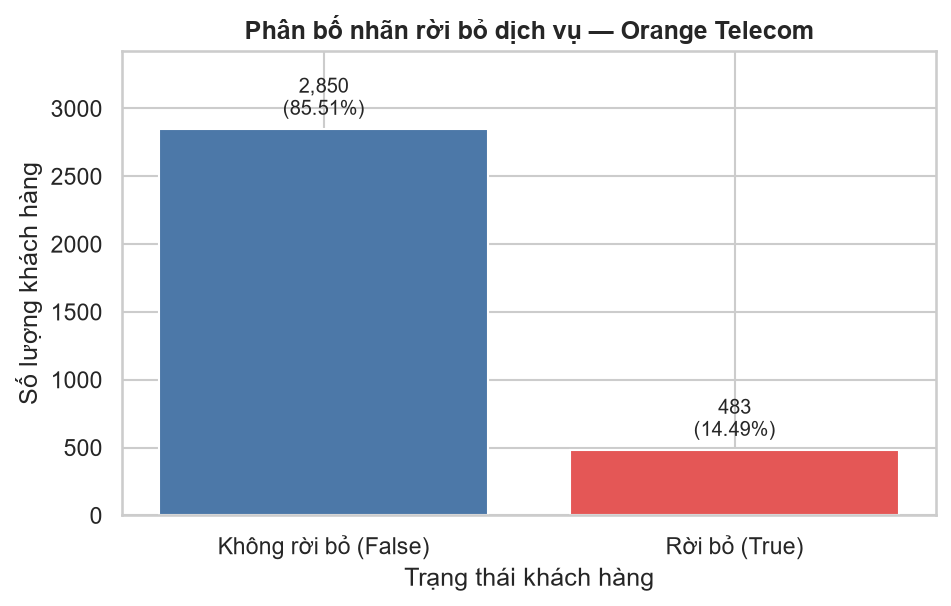

In [2]:
ORANGE_PATH = PROJECT_ROOT / "data" / "raw" / "orange-telecom" / "telecom_churn.csv"
df = pd.read_csv(ORANGE_PATH)
df["Churn_bin"] = df["Churn"].astype(int)

print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Giá trị thiếu (NaN): {int(df.isna().sum().sum())}")
print(f"Dòng trùng lặp: {int(df.duplicated().sum())}")

churn_counts = df["Churn_bin"].value_counts().sort_index()
print(f"Tỉ lệ Churn: {df['Churn_bin'].mean():.2%} (True={churn_counts[1]:,}, False={churn_counts[0]:,})")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(
    ["Không rời bỏ (False)", "Rời bỏ (True)"],
    [churn_counts[0], churn_counts[1]],
    color=["#4C78A8", "#E45756"],
)
for bar in bars:
    h = bar.get_height()
    ax.annotate(
        f"{h:,}\n({h / len(df):.2%})",
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9.5,
    )
ax.set_title("Phân bố nhãn rời bỏ dịch vụ — Orange Telecom", fontweight="bold")
ax.set_xlabel("Trạng thái khách hàng")
ax.set_ylabel("Số lượng khách hàng")
ax.set_ylim(0, max(churn_counts) * 1.2)
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "orange_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Tỉ lệ Churn theo gói cước & số lần gọi CSKH

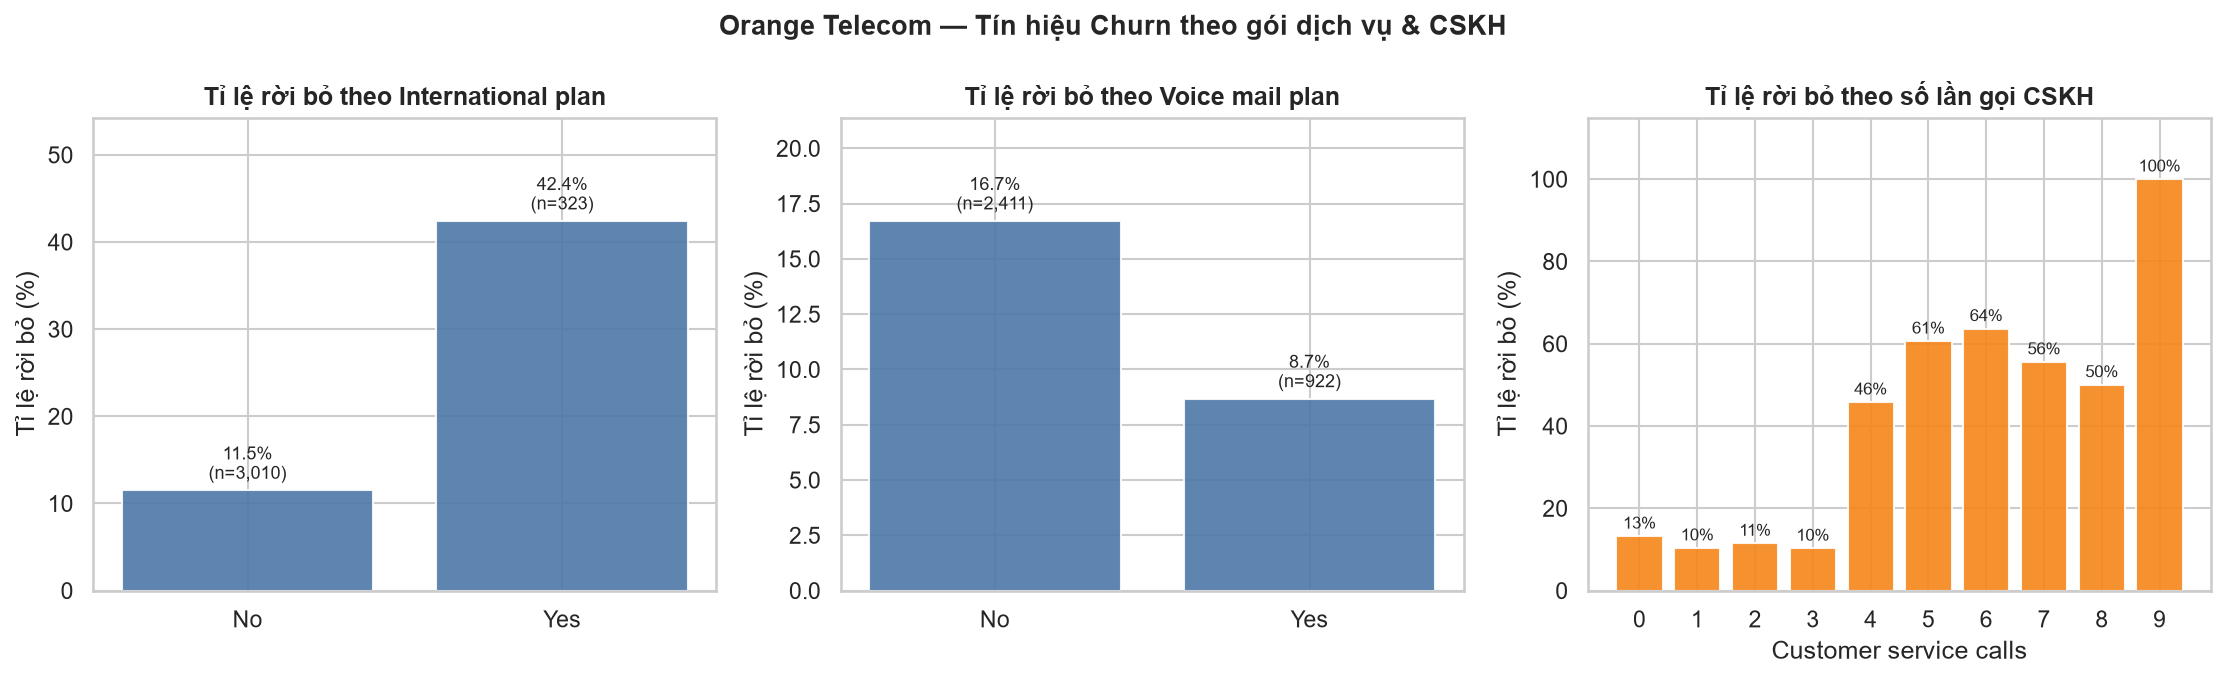

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

for ax, col in zip(axes[:2], ["International plan", "Voice mail plan"]):
    summary = df.groupby(col)["Churn_bin"].agg(["mean", "count"]).sort_index()
    bars = ax.bar(summary.index.astype(str), summary["mean"] * 100, color="#4C78A8", alpha=0.9)
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.annotate(
            f"{row['mean']:.1%}\n(n={int(row['count']):,})",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
        )
    ax.set_title(f"Tỉ lệ rời bỏ theo {col}", fontweight="bold")
    ax.set_ylabel("Tỉ lệ rời bỏ (%)")
    ax.set_ylim(0, max(summary["mean"] * 100) * 1.28)

csc = df.groupby("Customer service calls")["Churn_bin"].agg(["mean", "count"]).sort_index()
bars = axes[2].bar(csc.index.astype(str), csc["mean"] * 100, color="#F58518", alpha=0.9)
for bar, (_, row) in zip(bars, csc.iterrows()):
    axes[2].annotate(
        f"{row['mean']:.0%}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 2),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
    )
axes[2].set_title("Tỉ lệ rời bỏ theo số lần gọi CSKH", fontweight="bold")
axes[2].set_xlabel("Customer service calls")
axes[2].set_ylabel("Tỉ lệ rời bỏ (%)")
axes[2].set_ylim(0, 115)

fig.suptitle("Orange Telecom — Tín hiệu Churn theo gói dịch vụ & CSKH", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "orange_categorical_churn.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Phân bố biến số theo nhãn (`Total day minutes`, `Customer service calls`)

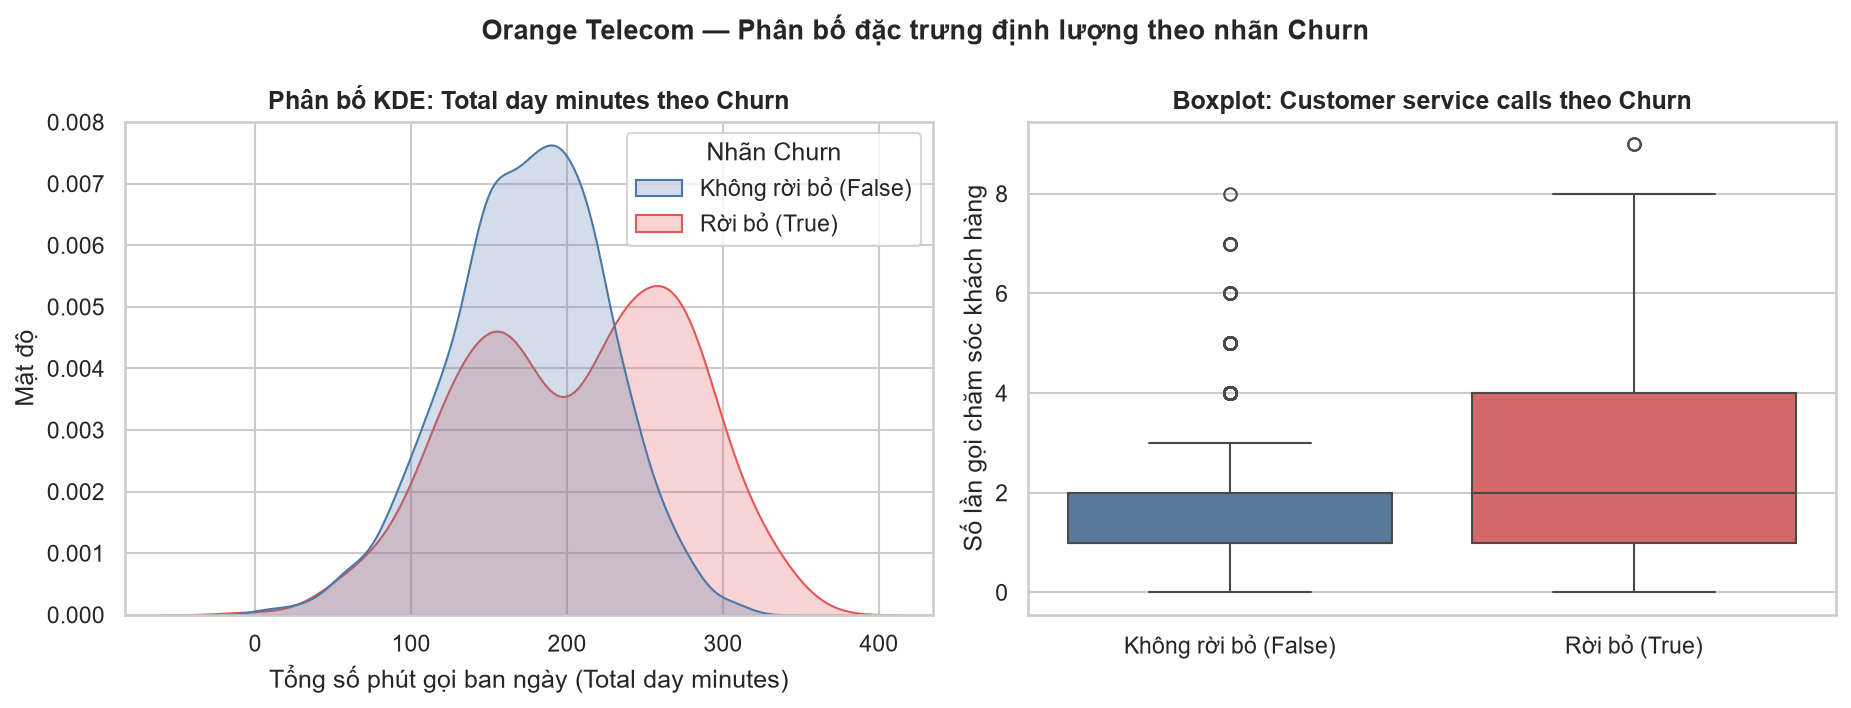

In [4]:
df_plot = df.copy()
df_plot["Nhãn Churn"] = df_plot["Churn_bin"].map({0: "Không rời bỏ (False)", 1: "Rời bỏ (True)"})

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
sns.kdeplot(
    data=df_plot,
    x="Total day minutes",
    hue="Nhãn Churn",
    fill=True,
    common_norm=False,
    palette={"Không rời bỏ (False)": "#4C78A8", "Rời bỏ (True)": "#E45756"},
    ax=axes[0],
)
axes[0].set_title("Phân bố KDE: Total day minutes theo Churn", fontweight="bold")
axes[0].set_xlabel("Tổng số phút gọi ban ngày (Total day minutes)")
axes[0].set_ylabel("Mật độ")

sns.boxplot(
    data=df_plot,
    x="Nhãn Churn",
    y="Customer service calls",
    hue="Nhãn Churn",
    palette={"Không rời bỏ (False)": "#4C78A8", "Rời bỏ (True)": "#E45756"},
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Boxplot: Customer service calls theo Churn", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Số lần gọi chăm sóc khách hàng")

fig.suptitle("Orange Telecom — Phân bố đặc trưng định lượng theo nhãn Churn", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "orange_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Kiểm chứng biến dư thừa (`Total * charge` tỉ lệ tuyến tính với `Total * minutes`)

Total day minutes vs Total day charge: Pearson r = 1.000000 (R^2 = 1.000000)
Total eve minutes vs Total eve charge: Pearson r = 1.000000 (R^2 = 1.000000)
Total night minutes vs Total night charge: Pearson r = 0.999999 (R^2 = 0.999998)
Total intl minutes vs Total intl charge: Pearson r = 0.999993 (R^2 = 0.999985)


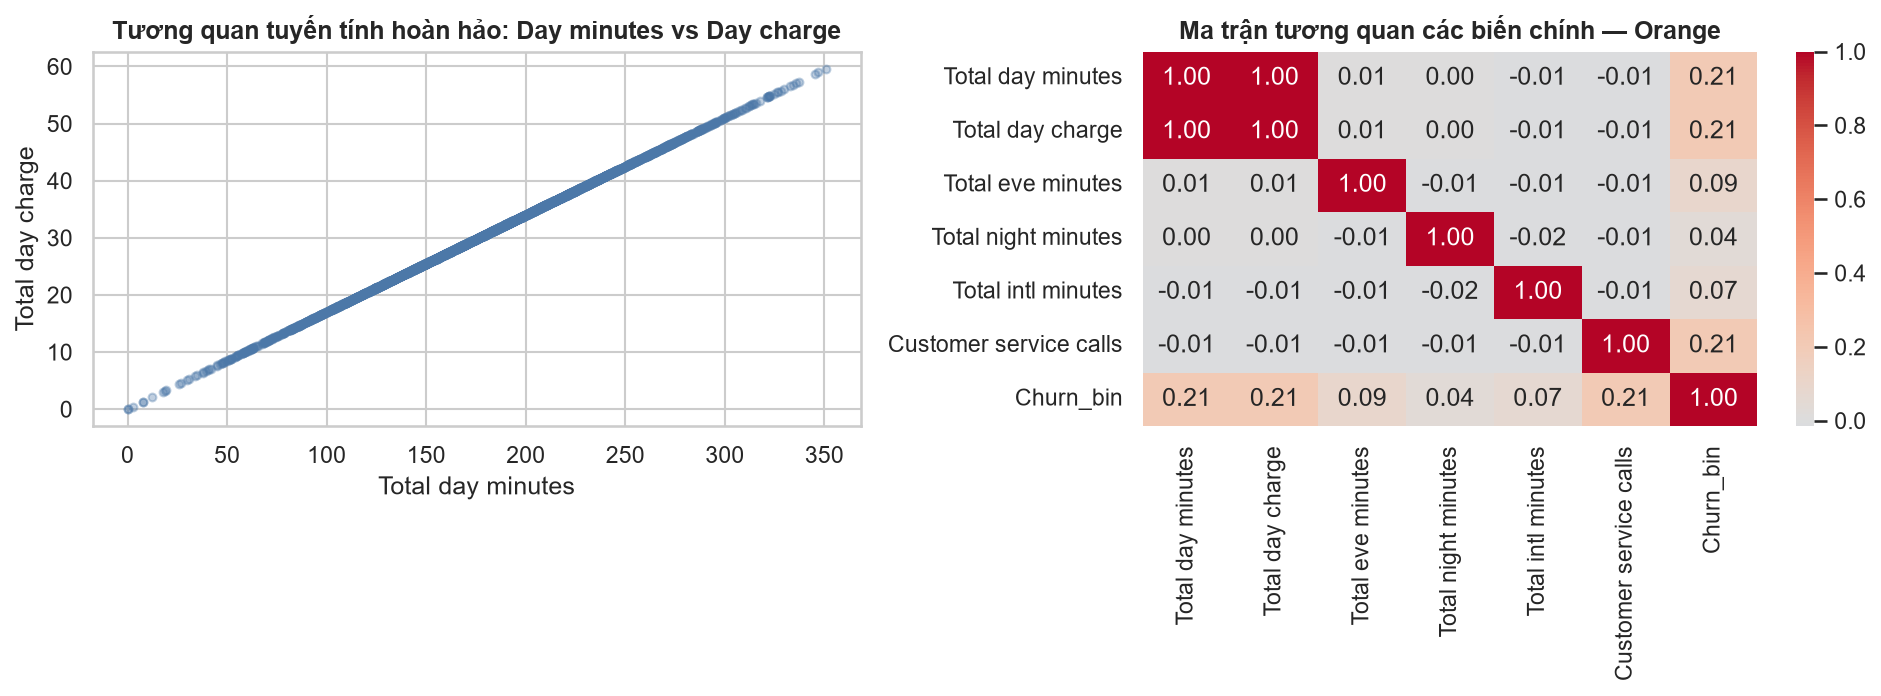

In [5]:
pairs = [
    ("Total day minutes", "Total day charge"),
    ("Total eve minutes", "Total eve charge"),
    ("Total night minutes", "Total night charge"),
    ("Total intl minutes", "Total intl charge"),
]
for m_col, c_col in pairs:
    r = df[m_col].corr(df[c_col])
    print(f"{m_col} vs {c_col}: Pearson r = {r:.6f} (R^2 = {r**2:.6f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(df["Total day minutes"], df["Total day charge"], alpha=0.35, s=14, color="#4C78A8")
axes[0].set_title("Tương quan tuyến tính hoàn hảo: Day minutes vs Day charge", fontweight="bold")
axes[0].set_xlabel("Total day minutes")
axes[0].set_ylabel("Total day charge")

key_num = [
    "Total day minutes", "Total day charge",
    "Total eve minutes", "Total night minutes",
    "Total intl minutes", "Customer service calls", "Churn_bin",
]
sns.heatmap(df[key_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Ma trận tương quan các biến chính — Orange", fontweight="bold")

fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "orange_correlation_redundancy.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Phát hiện → Hệ quả cho mô hình

1. **Mất cân bằng lớp (14.49% churn):** Cần đánh giá bằng PR-AUC, F1, Recall và ngưỡng tối ưu chi phí thay vì chỉ dựa vào Accuracy.
2. **Ngưỡng phi tuyến rất rõ ở `Total day minutes` và `Customer service calls`:** Khách hàng gọi CSKH $\ge 4$ lần hoặc gọi ban ngày cao (> ~250 phút) có tỉ lệ churn tăng vọt, trong khi trung vị giữa hai nhóm gần nhau. → **Hệ quả:** Giải thích vì sao Random Forest (AP ≈ 0.768) vượt trội rõ rệt so với Logistic Regression (AP ≈ 0.392) trên bộ dữ liệu này.
3. **Các cặp `Total * charge` tỉ lệ tuyến tính hoàn hảo với `Total * minutes` ($r = 1.0000$):** Có 4 cặp biến dư thừa hoàn toàn về mặt tuyến tính (cước = phút × đơn giá cố định). → **Hệ quả:** Cần lưu ý đa cộng tuyến cho các mô hình tuyến tính/khoảng cách (SVM, KNN, LogReg) hoặc xem xét loại bỏ bớt trong phân tích đặc trưng.